# *Dataset: Student Alcohol Consumption*

Os dados foram obtidos por meio de uma pesquisa com estudantes do ensino secundário que cursavam Matemática e Língua Portuguesa. O conjunto de dados contém diversas **informações sobre os aspectos sociais, o gênero e os hábitos de estudo dos estudantes.**

# *Dicionário*

Atributos presentes nos dois conjuntos de dados: `student-mat.csv` (curso de Matemática) e `student-por.csv` (curso de Língua Portuguesa).

1. escola — Escola do estudante (binária: `'GP'` — Gabriel Pereira ou `'MS'` — Mousinho da Silveira).

2. sexo — Sexo do estudante (binária: `'F'` — feminino ou `'M'` — masculino).

3. idade — Idade do estudante (numérica: de 15 a 22 anos).

4. regiao — Tipo de endereço residencial do estudante (binária: `'U'` — urbano ou `'R'` — rural).

5. tamanho_familia — Tamanho da família (binária: `'LE3'` — menor ou igual a 3 pessoas ou `'GT3'` — maior que 3 pessoas).

6. convivencia_pais — Situação de convivência dos pais (binária: `'T'` — moram juntos ou `'A'` — moram separados).

7. educacao_mae — Escolaridade da mãe (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

8. educacao_pai — Escolaridade do pai (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

9. trabalho_mae — Profissão da mãe (categórica nominal: `'teacher'` — professora; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

10. trabalho_pai — Profissão do pai (categórica nominal: `'teacher'` — professor; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

11. escolha_escola — Motivo para escolher a escola (categórica nominal: proximidade de `'home'` — casa; reputação da escola (`'reputation'`); preferência pelo curso (`'course'`); ou outro motivo (`'other'`)).

12. guardiao_legal — Responsável legal pelo estudante (categórica nominal: `'mother'` — mãe; `'father'` — pai; ou `'other'` — outro).

13. tempo_viagem_escola — Tempo de deslocamento de casa até a escola (numérica: 1 — menos de 15 minutos; 2 — de 15 a 30 minutos; 3 — de 30 minutos a 1 hora; ou 4 — mais de 1 hora).

14. tempo_estudo_semanal — Tempo semanal de estudo (numérica: 1 — menos de 2 horas; 2 — de 2 a 5 horas; 3 — de 5 a 10 horas; ou 4 — mais de 10 horas).

15. nº_reprovacoes — Número de reprovações anteriores (numérica: indica o número de reprovações quando 1≤n<31 \leq n < 31≤n<3; caso contrário, o valor é 4).

16. apoio_escola — Recebe apoio educacional extra da escola (binária: sim ou não).

17. apoio_familiar — Recebe apoio educacional da família (binária: sim ou não).

18. paid — Participa de aulas particulares pagas na disciplina correspondente (Matemática ou Língua Portuguesa) (binária: sim ou não).

19. participacao_atividades_extras — Participa de atividades extracurriculares (binária: sim ou não).

20. edu_infantil — Frequentou a educação infantil (binária: sim ou não).

21. desejo_de_ensino superior — Deseja cursar o ensino superior (binária: sim ou não).

22. acesso_internet_casa — Possui acesso à internet em casa (binária: sim ou não).

23. relacionamento_amoroso — Está em um relacionamento amoroso (binária: sim ou não).

24. qualidade_relacao_familiar — Qualidade das relações familiares (numérica: de 1 — muito ruim a 5 — excelente).

25. tempo_livre — Tempo livre após as aulas (numérica: de 1 — muito baixo a 5 — muito alto).

26. frequencia_saida_com_amigos — Frequência com que sai com os amigos (numérica: de 1 — muito baixa a 5 — muito alta).

27. consumo_alcool_semana — Consumo de álcool durante os dias úteis (numérica: de 1 — muito baixo a 5 — muito alto).

28. consumo_alcool_fim_de_semana — Consumo de álcool durante os fins de semana (numérica: de 1 — muito baixo a 5 — muito alto).

29. estado_saude_atual — Estado de saúde atual (numérica: de 1 — muito ruim a 5 — muito bom).

30. faltas — Número de faltas escolares (numérica: de 0 a 93).

31. nota_1p — Nota do primeiro período (numérica: de 0 a 20).

32. nota_2p — Nota do segundo período (numérica: de 0 a 20).

33. nota_final — Nota final (numérica: de 0 a 20; variável-alvo para previsão).

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import numpy as np

In [63]:
df_port = pd.read_csv('files/student-por.csv')
df_mat = pd.read_csv('files/student-mat.csv')

In [64]:
# Retirando algumas colunas.
df_port = df_port.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])
df_mat = df_mat.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])

# Renomeando as colunas sobrantes:
df_port = df_port.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})

df_mat = df_mat.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})


## Boxplots que geram os quartis das variáveis nominais por dataframe


In [65]:
def boxplots_nominais(df, col_nota, nominais):

    for col in nominais:
        print(f"\n===== {col_nota} por {col} =====")
        print(df.groupby(col)[col_nota].describe().round(1))   # tabela com os quartis

        plt.figure(figsize=(7, 4))
        sns.boxplot(data=df, x=col, y=col_nota)
        plt.title(f"{col_nota} por {col}")
        plt.show()

## Notas no dataframe de Português


===== nota_1p por sexo =====
      count  mean  std  min   25%   50%   75%   max
sexo                                               
F     383.0  11.6  2.8  0.0  10.0  12.0  14.0  19.0
M     266.0  11.1  2.6  4.0   9.0  11.0  13.0  18.0


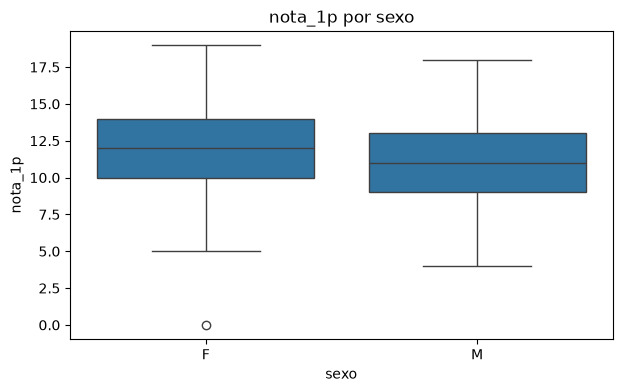


===== nota_1p por regiao =====
        count  mean  std  min   25%   50%   75%   max
regiao                                               
R       197.0  10.7  2.7  4.0   9.0  10.0  13.0  18.0
U       452.0  11.7  2.7  0.0  10.0  12.0  14.0  19.0


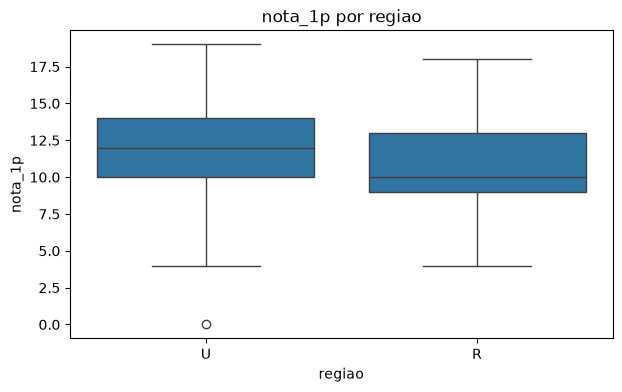


===== nota_1p por desejo_de_ensino_superior =====
                           count  mean  std  min   25%   50%   75%   max
desejo_de_ensino_superior                                               
no                          69.0   8.6  1.9  4.0   8.0   9.0  10.0  14.0
yes                        580.0  11.7  2.6  0.0  10.0  12.0  14.0  19.0


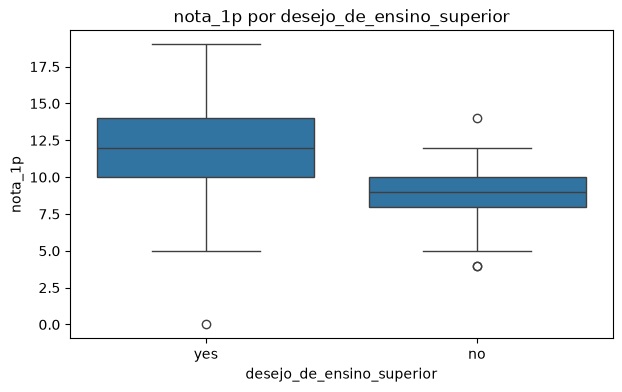


===== nota_1p por tamanho_familia =====
                 count  mean  std  min   25%   50%   75%   max
tamanho_familia                                               
GT3              457.0  11.3  2.8  0.0   9.0  11.0  13.0  18.0
LE3              192.0  11.6  2.7  5.0  10.0  11.0  14.0  19.0


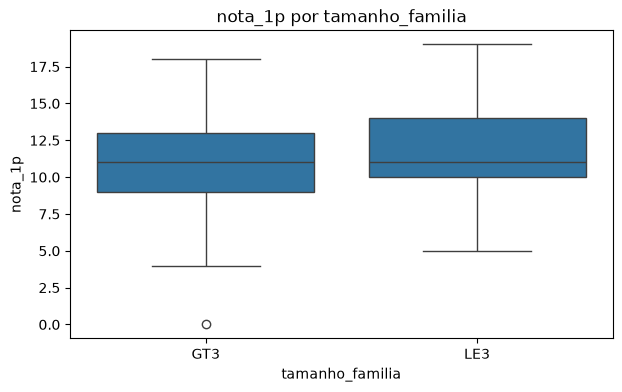


===== nota_1p por convivencia_pais =====
                  count  mean  std  min   25%   50%   75%   max
convivencia_pais                                               
A                  80.0  11.3  3.0  0.0  10.0  11.5  13.0  17.0
T                 569.0  11.4  2.7  4.0  10.0  11.0  13.0  19.0


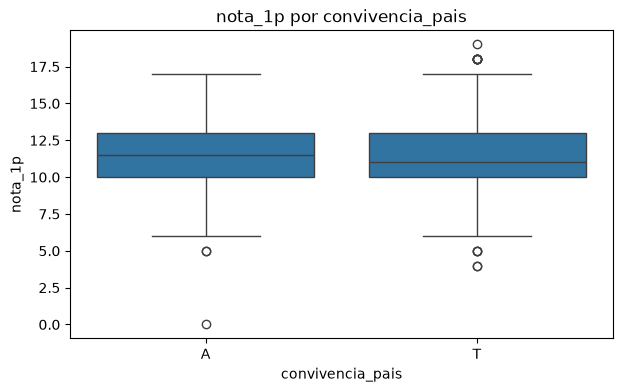


===== nota_1p por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home       135.0  10.5  2.9  0.0   9.0  10.0  12.0  19.0
health         48.0  12.4  2.9  7.0  10.0  12.0  14.0  18.0
other         258.0  11.3  2.6  5.0   9.0  11.0  13.0  17.0
services      136.0  11.6  2.6  4.0  10.0  11.0  13.0  18.0
teacher        72.0  12.6  2.8  5.0  11.0  13.0  14.2  18.0


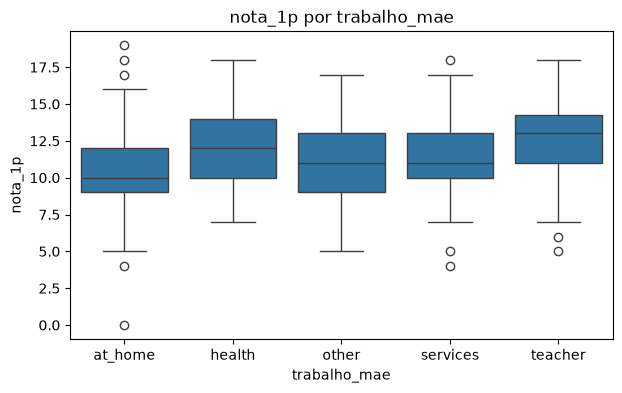


===== nota_1p por trabalho_pai =====
              count  mean  std  min   25%   50%   75%   max
trabalho_pai                                               
at_home        42.0  10.4  2.8  4.0   9.0  10.0  12.0  18.0
health         23.0  12.0  3.0  5.0  10.0  11.0  14.0  18.0
other         367.0  11.4  2.6  4.0  10.0  11.0  13.0  18.0
services      181.0  11.3  2.7  5.0  10.0  11.0  13.0  19.0
teacher        36.0  13.1  3.4  0.0  12.0  13.0  15.2  18.0


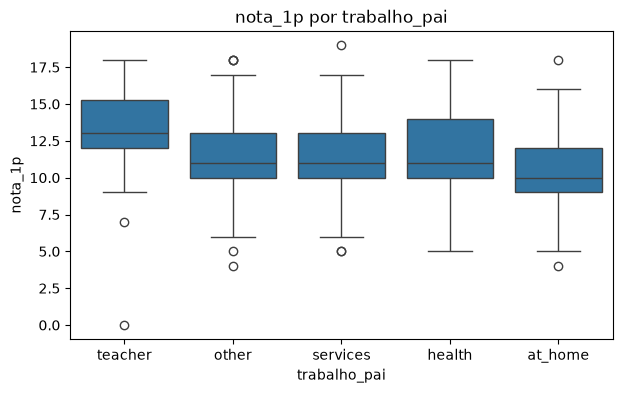


===== nota_1p por motivo_escola =====
               count  mean  std  min   25%   50%   75%   max
motivo_escola                                               
course         285.0  11.0  2.8  0.0   9.0  11.0  13.0  19.0
home           149.0  11.7  2.4  5.0  10.0  11.0  14.0  18.0
other           72.0  10.7  2.8  5.0   9.0  11.0  12.2  18.0
reputation     143.0  12.3  2.7  5.0  11.0  12.0  14.0  18.0


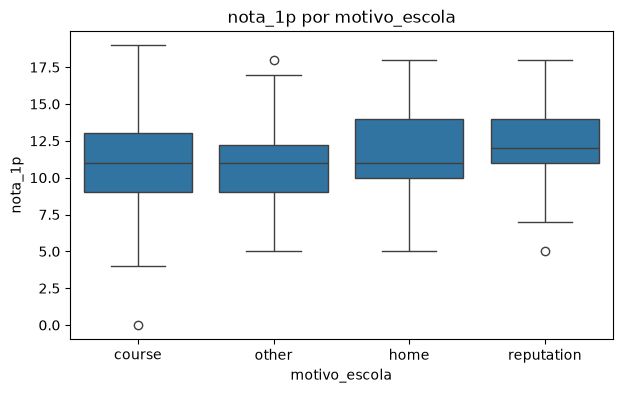


===== nota_1p por guardiao_legal =====
                count  mean  std  min   25%   50%   75%   max
guardiao_legal                                               
father          153.0  11.8  2.6  5.0  10.0  12.0  14.0  19.0
mother          455.0  11.4  2.8  0.0  10.0  11.0  13.0  18.0
other            41.0  10.1  2.1  7.0   9.0  10.0  12.0  14.0


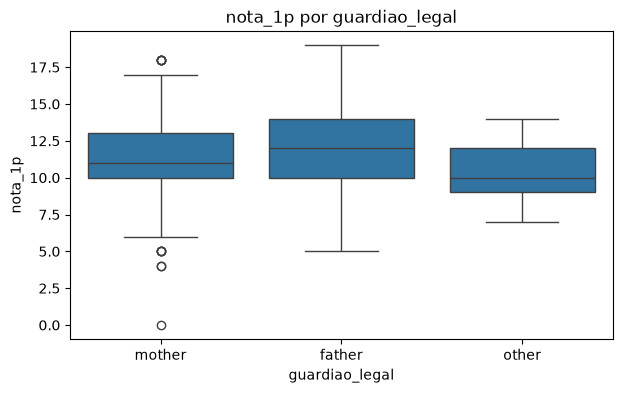

In [66]:
nominais = ["sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia", "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"] # complete com as suas
boxplots_nominais(df_port, "nota_1p", nominais)


===== nota_2p por sexo =====
      count  mean  std  min   25%   50%   75%   max
sexo                                               
F     383.0  11.8  3.0  0.0  10.0  12.0  14.0  19.0
M     266.0  11.2  2.8  0.0   9.0  11.0  13.0  18.0


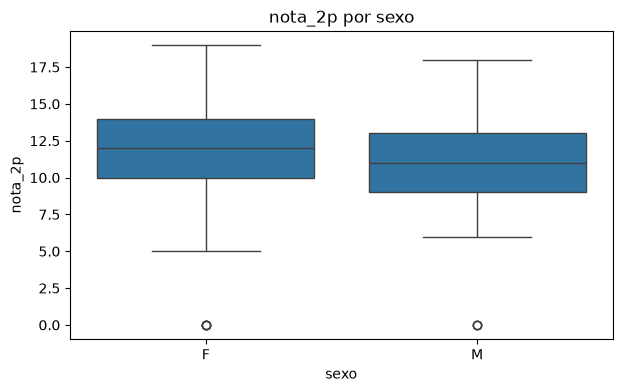


===== nota_2p por regiao =====
        count  mean  std  min   25%   50%   75%   max
regiao                                               
R       197.0  10.9  3.1  0.0   9.0  11.0  13.0  19.0
U       452.0  11.9  2.8  0.0  10.0  12.0  14.0  18.0


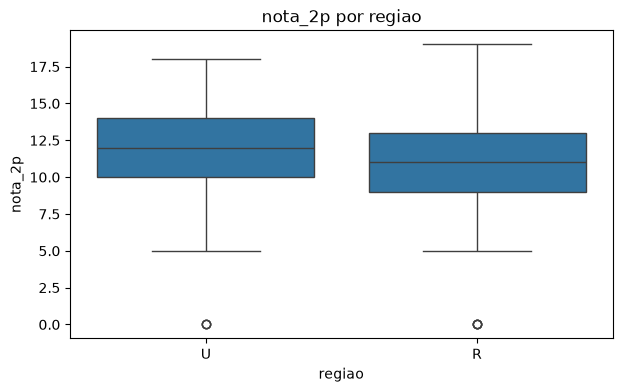


===== nota_2p por desejo_de_ensino_superior =====
                           count  mean  std  min   25%   50%   75%   max
desejo_de_ensino_superior                                               
no                          69.0   8.8  2.5  0.0   8.0   9.0  10.0  13.0
yes                        580.0  11.9  2.8  0.0  10.0  12.0  14.0  19.0


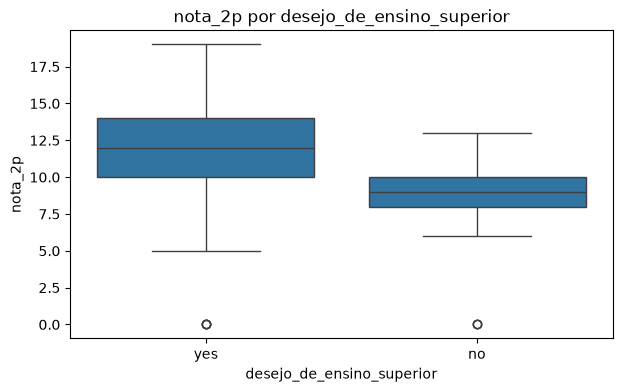


===== nota_2p por tamanho_familia =====
                 count  mean  std  min   25%   50%   75%   max
tamanho_familia                                               
GT3              457.0  11.5  3.0  0.0  10.0  11.0  13.0  18.0
LE3              192.0  11.7  2.7  0.0  10.0  11.0  14.0  19.0


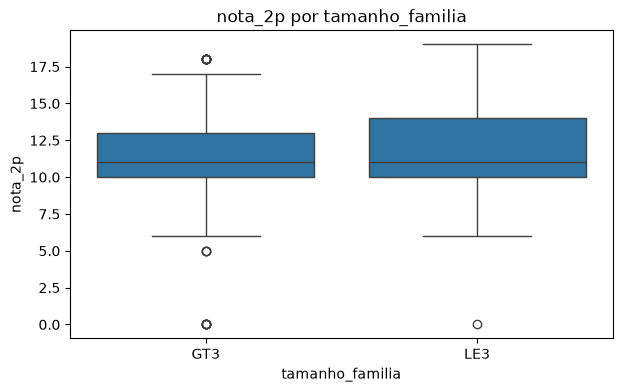


===== nota_2p por convivencia_pais =====
                  count  mean  std  min   25%   50%   75%   max
convivencia_pais                                               
A                  80.0  11.4  3.2  0.0  10.0  11.5  13.2  18.0
T                 569.0  11.6  2.9  0.0  10.0  11.0  13.0  19.0


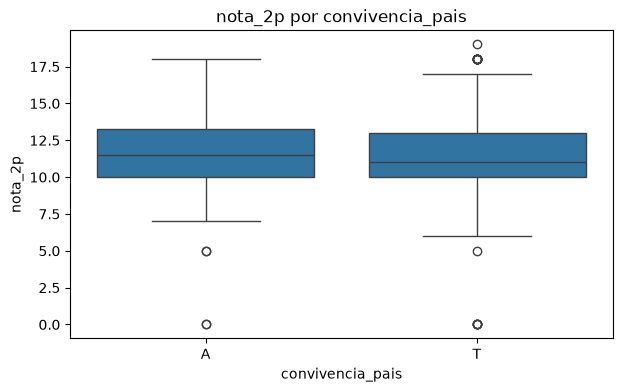


===== nota_2p por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home       135.0  10.7  3.0  0.0   9.0  10.0  12.0  18.0
health         48.0  12.6  2.8  7.0  10.0  12.5  15.0  18.0
other         258.0  11.4  2.8  0.0   9.0  11.5  13.0  18.0
services      136.0  11.7  2.8  0.0  10.0  12.0  13.0  19.0
teacher        72.0  12.7  3.0  0.0  11.0  13.0  14.0  18.0


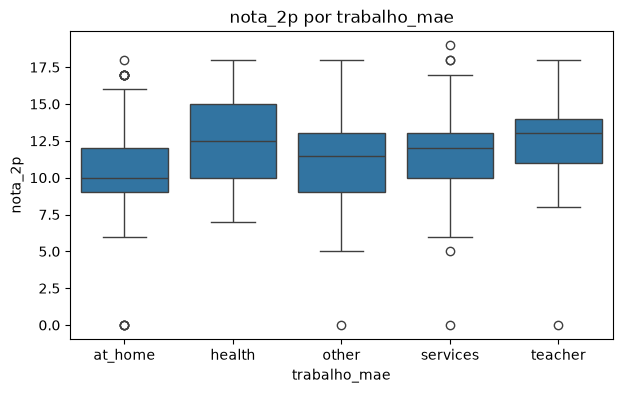


===== nota_2p por trabalho_pai =====
              count  mean  std  min   25%   50%   75%   max
trabalho_pai                                               
at_home        42.0  10.8  3.1  0.0   9.0  11.0  13.0  18.0
health         23.0  12.3  2.9  6.0  10.0  12.0  15.0  18.0
other         367.0  11.5  2.8  0.0  10.0  11.0  13.0  19.0
services      181.0  11.4  2.9  0.0  10.0  11.0  13.0  18.0
teacher        36.0  13.3  2.9  5.0  11.8  13.0  15.2  18.0


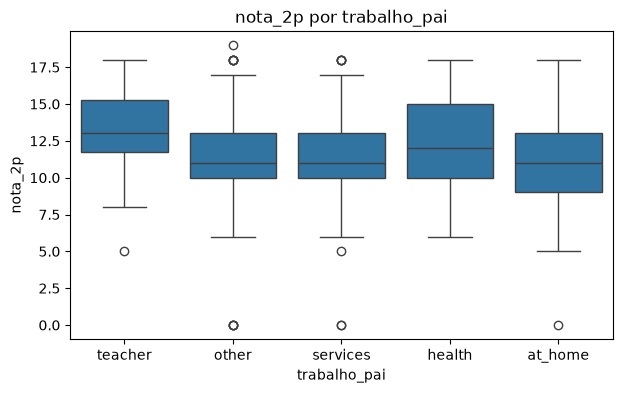


===== nota_2p por motivo_escola =====
               count  mean  std  min   25%   50%   75%   max
motivo_escola                                               
course         285.0  11.1  2.9  0.0  10.0  11.0  13.0  18.0
home           149.0  11.8  2.6  0.0  10.0  12.0  13.0  18.0
other           72.0  10.8  3.0  0.0   9.0  11.0  12.2  18.0
reputation     143.0  12.6  3.0  0.0  11.0  13.0  15.0  19.0


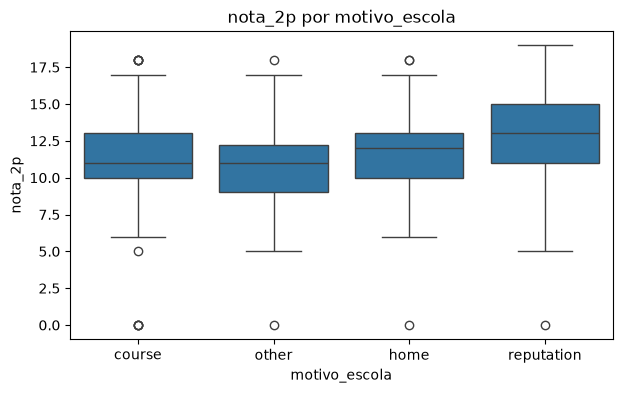


===== nota_2p por guardiao_legal =====
                count  mean  std  min   25%   50%   75%   max
guardiao_legal                                               
father          153.0  11.9  2.8  0.0  10.0  12.0  13.0  18.0
mother          455.0  11.6  3.0  0.0  10.0  11.0  13.0  19.0
other            41.0  10.4  2.7  0.0   9.0  10.0  12.0  15.0


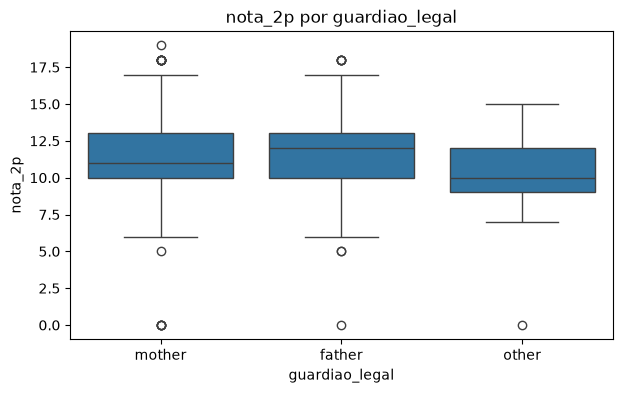

In [67]:
boxplots_nominais(df_port, "nota_2p", nominais)


===== nota_final por sexo =====
      count  mean  std  min   25%   50%   75%   max
sexo                                               
F     383.0  12.3  3.1  0.0  10.0  12.0  14.0  19.0
M     266.0  11.4  3.3  0.0  10.0  11.0  13.0  19.0


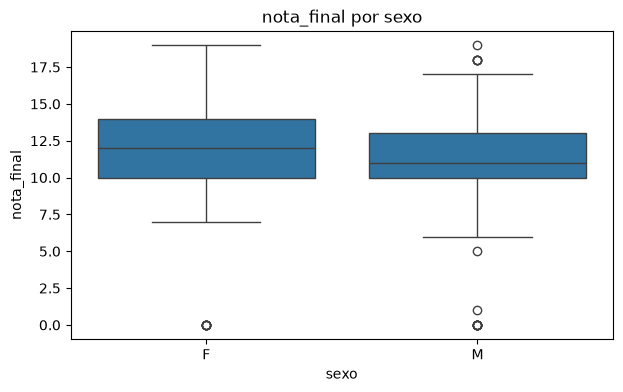


===== nota_final por regiao =====
        count  mean  std  min   25%   50%   75%   max
regiao                                               
R       197.0  11.1  3.6  0.0  10.0  11.0  13.0  19.0
U       452.0  12.3  3.0  0.0  10.0  12.0  14.0  19.0


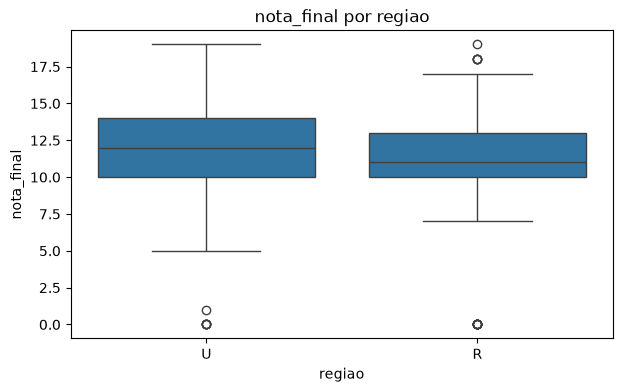


===== nota_final por desejo_de_ensino_superior =====
                           count  mean  std  min   25%   50%   75%   max
desejo_de_ensino_superior                                               
no                          69.0   8.8  3.0  0.0   8.0  10.0  10.0  14.0
yes                        580.0  12.3  3.1  0.0  10.8  12.0  14.0  19.0


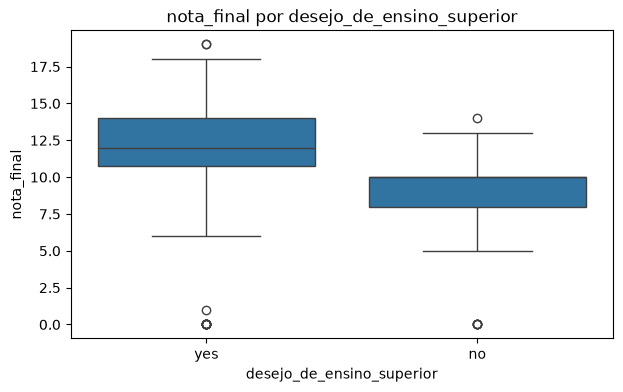


===== nota_final por tamanho_familia =====
                 count  mean  std  min   25%   50%   75%   max
tamanho_familia                                               
GT3              457.0  11.8  3.4  0.0  10.0  12.0  14.0  19.0
LE3              192.0  12.1  2.9  0.0  10.0  12.0  14.0  19.0


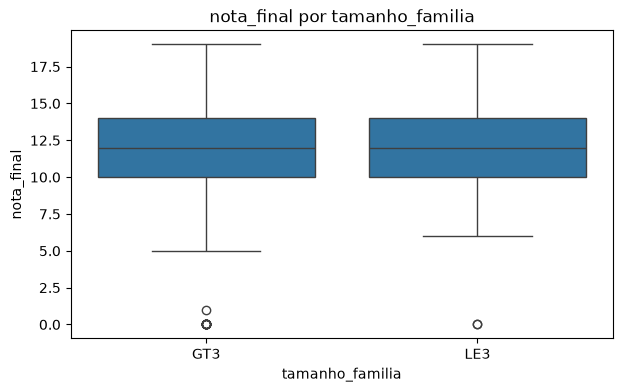


===== nota_final por convivencia_pais =====
                  count  mean  std  min   25%   50%   75%   max
convivencia_pais                                               
A                  80.0  11.9  3.2  0.0  10.0  12.0  14.0  18.0
T                 569.0  11.9  3.2  0.0  10.0  12.0  14.0  19.0


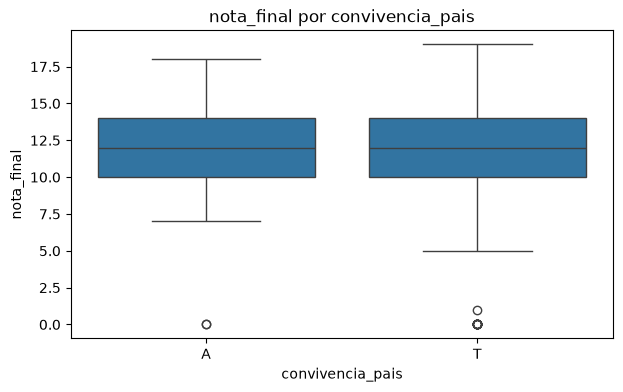


===== nota_final por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home       135.0  11.0  3.1  0.0  10.0  11.0  13.0  18.0
health         48.0  13.1  3.0  8.0  10.8  13.0  15.0  18.0
other         258.0  11.7  3.3  0.0  10.0  12.0  14.0  18.0
services      136.0  12.1  2.9  0.0  10.0  12.0  14.0  19.0
teacher        72.0  13.1  3.3  0.0  11.0  13.0  15.0  19.0


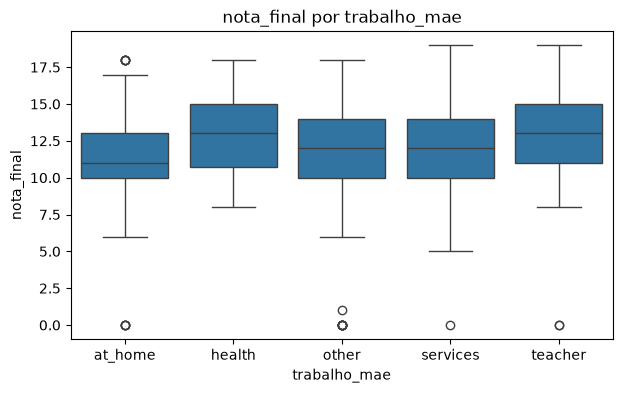


===== nota_final por trabalho_pai =====
              count  mean  std  min   25%   50%   75%   max
trabalho_pai                                               
at_home        42.0  11.4  3.2  0.0  10.0  11.0  14.0  18.0
health         23.0  12.6  3.1  6.0  10.0  12.0  15.0  18.0
other         367.0  11.9  3.1  0.0  10.0  12.0  14.0  19.0
services      181.0  11.6  3.4  0.0  10.0  12.0  14.0  18.0
teacher        36.0  13.6  3.4  0.0  12.0  14.0  16.0  19.0


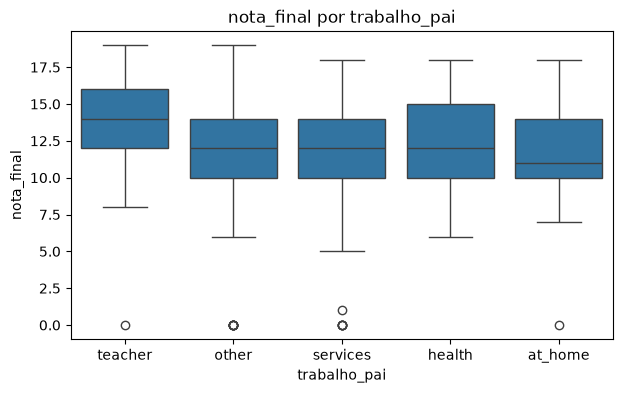


===== nota_final por motivo_escola =====
               count  mean  std  min   25%   50%   75%   max
motivo_escola                                               
course         285.0  11.5  3.1  0.0  10.0  11.0  14.0  18.0
home           149.0  12.2  3.0  0.0  11.0  12.0  14.0  19.0
other           72.0  10.7  3.9  0.0   9.8  11.0  13.0  18.0
reputation     143.0  12.9  3.1  0.0  11.0  13.0  15.0  19.0


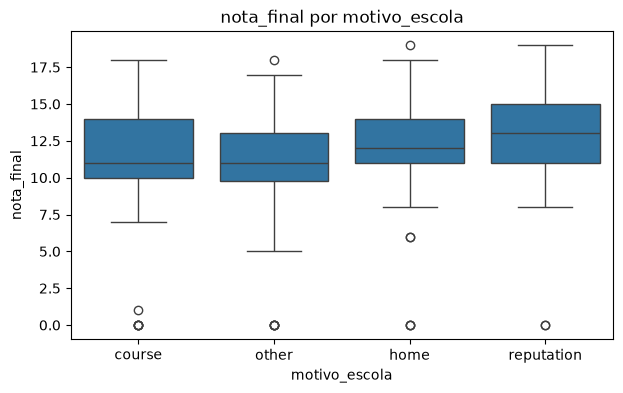


===== nota_final por guardiao_legal =====
                count  mean  std  min   25%   50%   75%   max
guardiao_legal                                               
father          153.0  12.2  3.2  0.0  11.0  12.0  14.0  19.0
mother          455.0  11.9  3.3  0.0  10.0  12.0  14.0  19.0
other            41.0  10.9  2.6  0.0  10.0  11.0  12.0  15.0


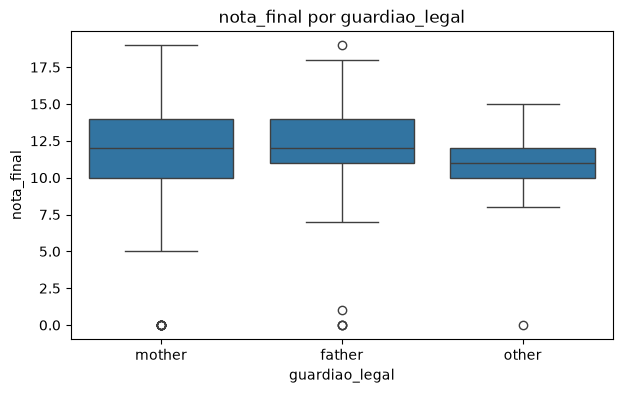

In [68]:
boxplots_nominais(df_port, "nota_final", nominais)

## Notas no dataframe de matemática


===== nota_1p por sexo =====
      count  mean  std  min  25%   50%   75%   max
sexo                                              
F     208.0  10.6  3.2  4.0  8.0  10.0  13.0  19.0
M     187.0  11.2  3.4  3.0  9.0  11.0  14.0  19.0


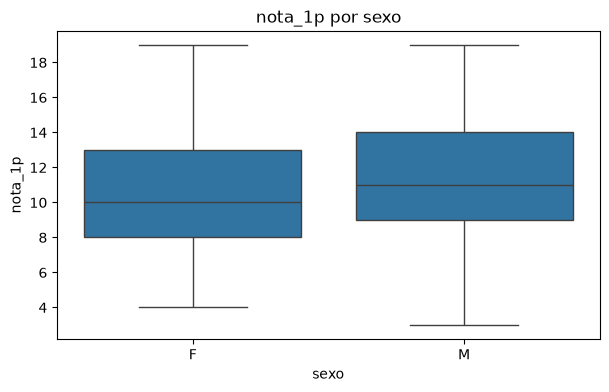


===== nota_1p por regiao =====
        count  mean  std  min  25%   50%   75%   max
regiao                                              
R        88.0  10.5  3.4  3.0  8.0  10.0  13.0  19.0
U       307.0  11.0  3.3  4.0  8.0  11.0  14.0  19.0


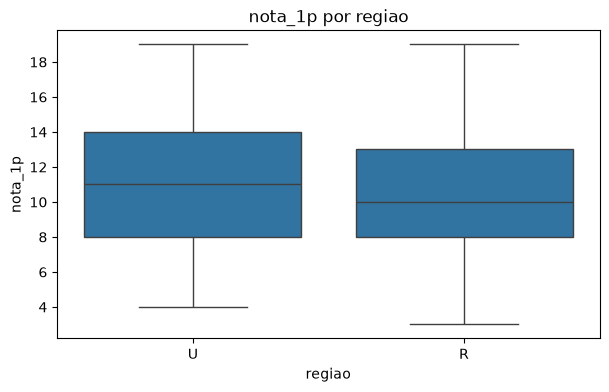


===== nota_1p por desejo_de_ensino_superior =====
                           count  mean  std  min  25%   50%   75%   max
desejo_de_ensino_superior                                              
no                          20.0   8.4  2.9  5.0  6.0   7.0  10.0  14.0
yes                        375.0  11.0  3.3  3.0  8.0  11.0  13.0  19.0


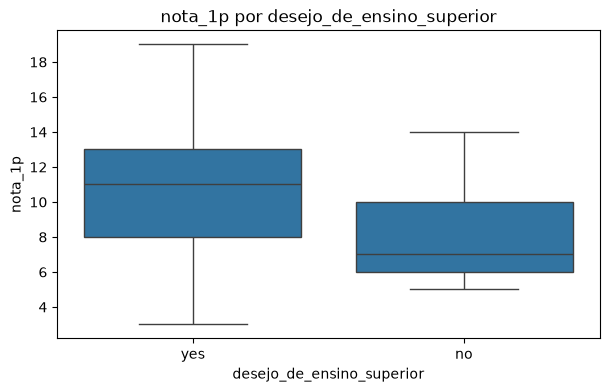


===== nota_1p por tamanho_familia =====
                 count  mean  std  min  25%   50%   75%   max
tamanho_familia                                              
GT3              281.0  10.8  3.3  4.0  8.0  10.0  13.0  19.0
LE3              114.0  11.3  3.3  3.0  8.2  11.0  14.0  19.0


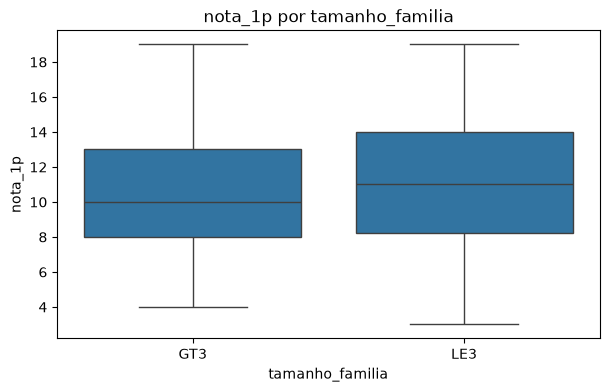


===== nota_1p por convivencia_pais =====
                  count  mean  std  min  25%   50%   75%   max
convivencia_pais                                              
A                  41.0  11.1  3.4  4.0  8.0  11.0  13.0  18.0
T                 354.0  10.9  3.3  3.0  8.0  11.0  13.0  19.0


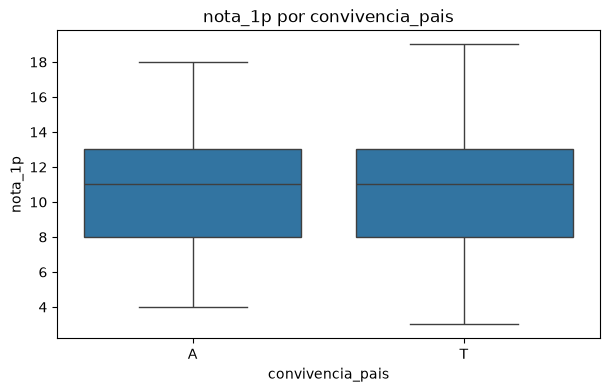


===== nota_1p por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home        59.0  10.5  3.3  5.0   8.0  10.0  12.5  18.0
health         34.0  12.2  3.1  6.0  10.0  13.0  14.0  19.0
other         141.0  10.2  3.1  3.0   8.0  10.0  13.0  19.0
services      103.0  11.4  3.5  5.0   8.0  11.0  14.0  19.0
teacher        58.0  11.5  3.2  6.0   9.0  11.0  14.0  18.0


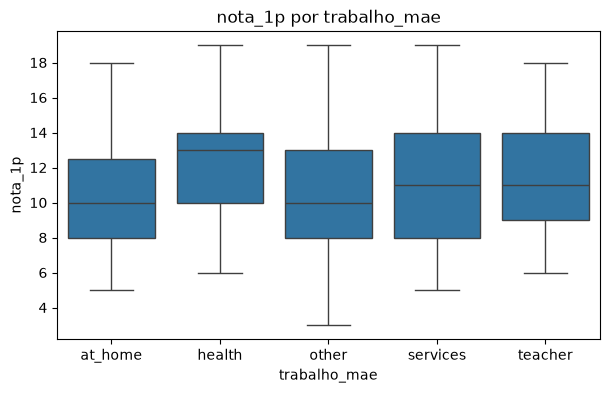


===== nota_1p por trabalho_pai =====
              count  mean  std  min   25%   50%   75%   max
trabalho_pai                                               
at_home        20.0  11.7  3.8  5.0   9.0  11.5  14.2  18.0
health         18.0  11.4  2.7  6.0  10.0  11.0  13.8  17.0
other         217.0  10.6  3.2  4.0   8.0  10.0  13.0  19.0
services      111.0  10.8  3.2  3.0   8.0  11.0  13.0  19.0
teacher        29.0  12.9  3.9  5.0  10.0  14.0  16.0  19.0


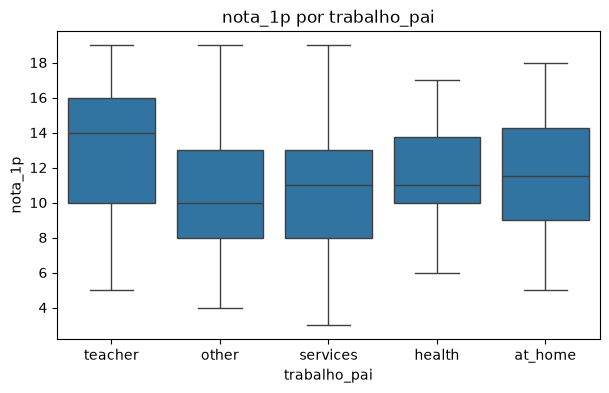


===== nota_1p por motivo_escola =====
               count  mean  std  min  25%   50%   75%   max
motivo_escola                                              
course         145.0  10.6  3.4  3.0  8.0  10.0  13.0  19.0
home           109.0  10.8  3.3  5.0  8.0  10.0  14.0  18.0
other           36.0  10.8  3.2  6.0  8.0  11.0  13.0  18.0
reputation     105.0  11.5  3.2  6.0  9.0  12.0  14.0  19.0


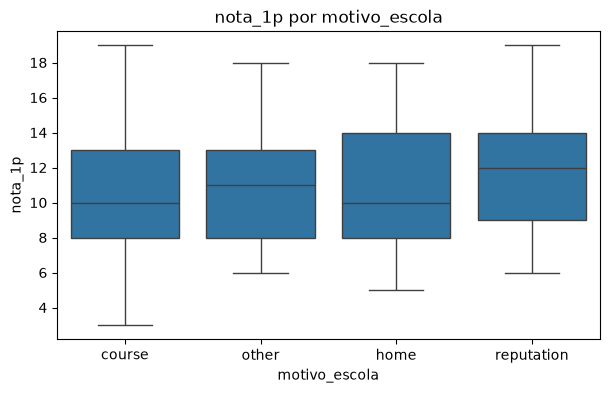


===== nota_1p por guardiao_legal =====
                count  mean  std  min  25%   50%   75%   max
guardiao_legal                                              
father           90.0  11.1  3.2  5.0  9.0  11.0  13.8  19.0
mother          273.0  10.9  3.4  3.0  8.0  11.0  13.0  19.0
other            32.0  10.6  3.2  4.0  8.0  10.0  13.2  17.0


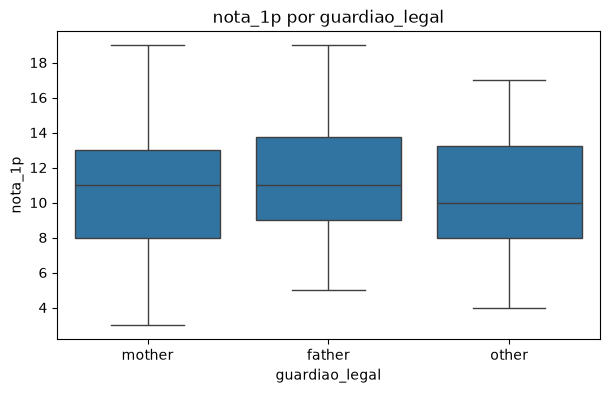

In [69]:
boxplots_nominais(df_mat, "nota_1p", nominais)


===== nota_2p por sexo =====
      count  mean  std  min  25%   50%   75%   max
sexo                                              
F     208.0  10.4  3.6  0.0  8.0  10.0  13.0  18.0
M     187.0  11.1  3.9  0.0  9.0  11.0  14.0  19.0


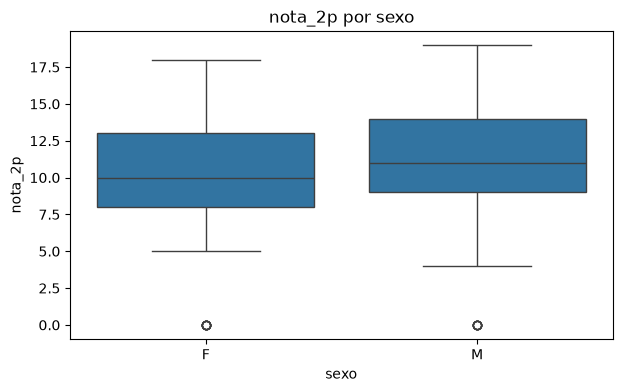


===== nota_2p por regiao =====
        count  mean  std  min  25%   50%   75%   max
regiao                                              
R        88.0   9.8  3.9  0.0  8.0  10.0  12.0  18.0
U       307.0  11.0  3.7  0.0  9.0  11.0  14.0  19.0


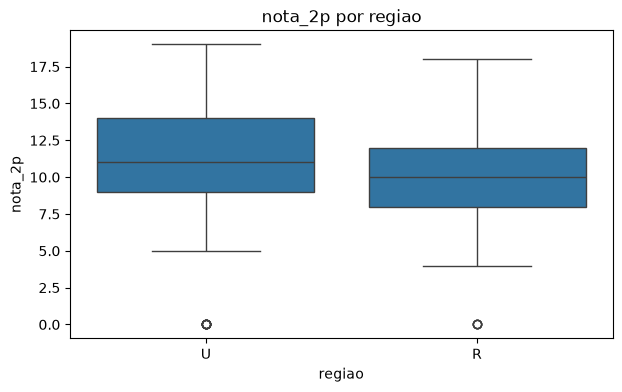


===== nota_2p por desejo_de_ensino_superior =====
                           count  mean  std  min  25%   50%   75%   max
desejo_de_ensino_superior                                              
no                          20.0   7.8  3.3  0.0  6.8   8.0  10.0  12.0
yes                        375.0  10.9  3.7  0.0  9.0  11.0  13.0  19.0


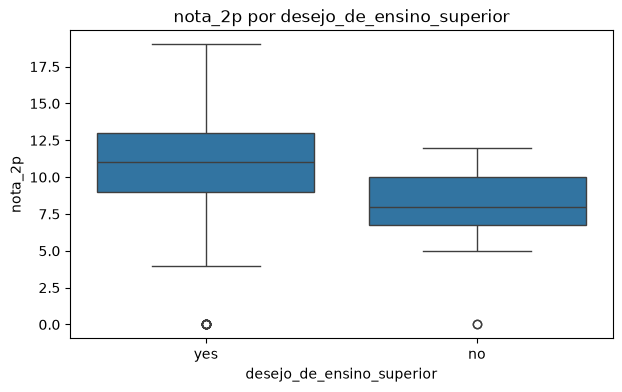


===== nota_2p por tamanho_familia =====
                 count  mean  std  min  25%   50%   75%   max
tamanho_familia                                              
GT3              281.0  10.5  3.9  0.0  8.0  10.0  13.0  19.0
LE3              114.0  11.2  3.5  0.0  9.0  11.0  13.0  19.0


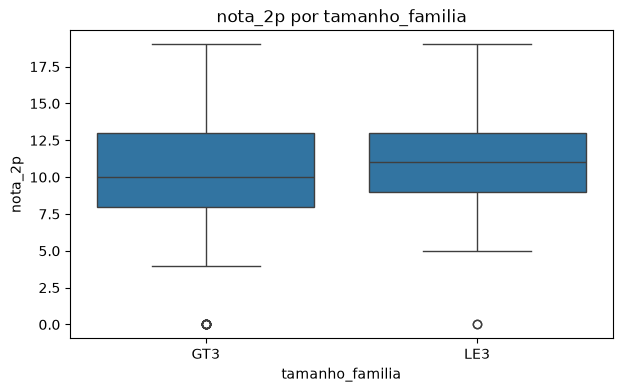


===== nota_2p por convivencia_pais =====
                  count  mean  std  min  25%   50%   75%   max
convivencia_pais                                              
A                  41.0  11.2  4.0  0.0  9.0  11.0  13.0  19.0
T                 354.0  10.7  3.7  0.0  9.0  11.0  13.0  19.0


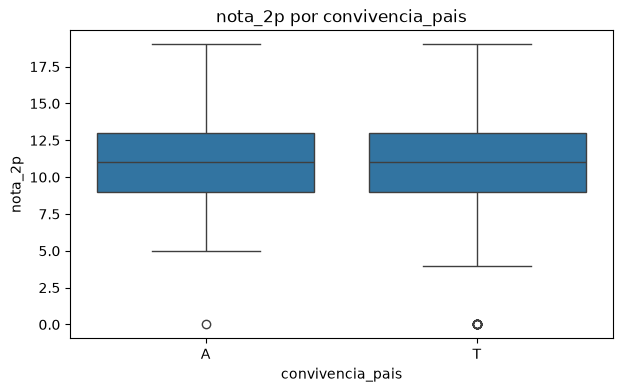


===== nota_2p por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home        59.0   9.7  3.7  0.0   8.0  10.0  12.0  18.0
health         34.0  12.4  3.0  7.0  10.0  13.0  14.8  19.0
other         141.0  10.2  3.6  0.0   8.0  10.0  13.0  18.0
services      103.0  11.2  4.1  0.0   9.0  12.0  14.0  18.0
teacher        58.0  11.2  3.6  0.0   9.0  11.0  14.0  19.0


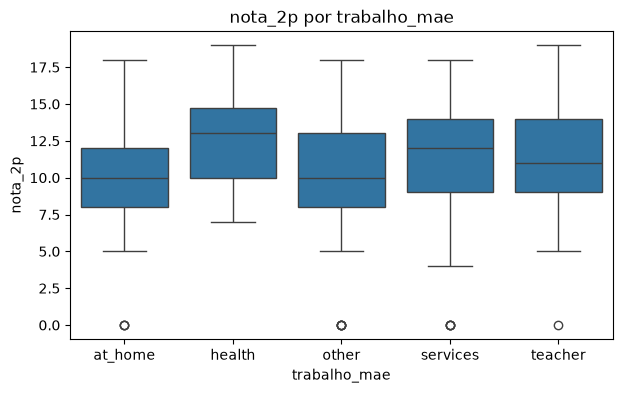


===== nota_2p por trabalho_pai =====
              count  mean  std  min  25%   50%   75%   max
trabalho_pai                                              
at_home        20.0  10.6  4.7  0.0  9.0  11.0  14.0  18.0
health         18.0  11.4  3.3  6.0  9.0  11.5  13.8  17.0
other         217.0  10.4  3.8  0.0  8.0  10.0  13.0  19.0
services      111.0  10.9  3.1  0.0  9.0  11.0  13.0  19.0
teacher        29.0  12.0  5.1  0.0  9.0  13.0  16.0  19.0


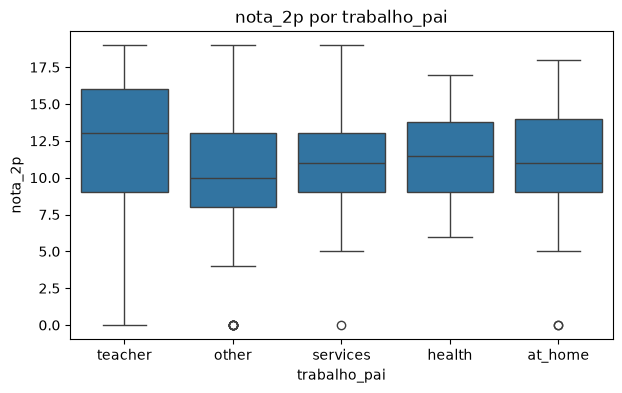


===== nota_2p por motivo_escola =====
               count  mean  std  min  25%   50%   75%   max
motivo_escola                                              
course         145.0  10.2  4.1  0.0  8.0  10.0  13.0  19.0
home           109.0  10.7  3.6  0.0  9.0  10.0  13.0  18.0
other           36.0  11.2  3.3  5.0  8.8  12.0  13.0  18.0
reputation     105.0  11.3  3.5  0.0  9.0  11.0  14.0  19.0


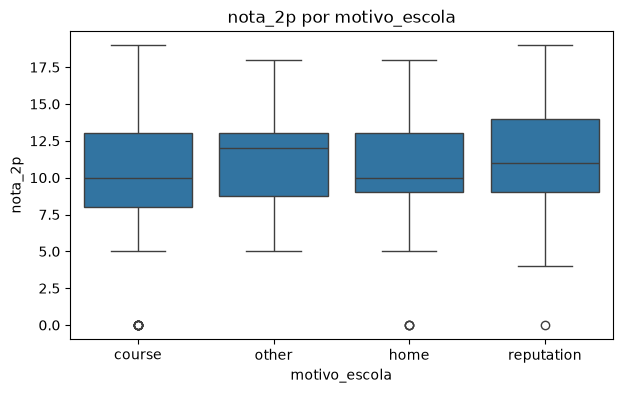


===== nota_2p por guardiao_legal =====
                count  mean  std  min  25%   50%   75%   max
guardiao_legal                                              
father           90.0  11.2  3.4  0.0  9.0  11.0  13.0  18.0
mother          273.0  10.7  3.9  0.0  9.0  11.0  13.0  19.0
other            32.0   9.8  3.7  0.0  8.0   9.5  12.0  18.0


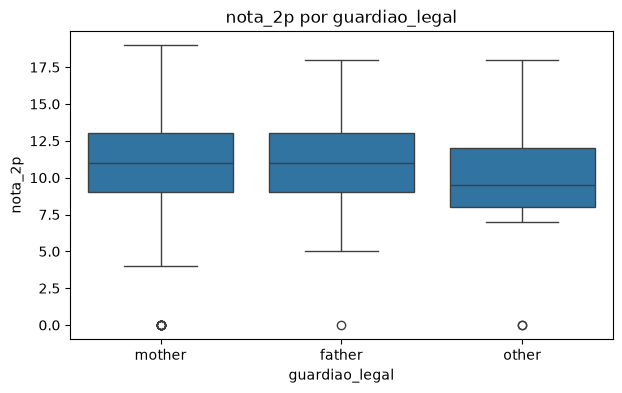

In [70]:
boxplots_nominais(df_mat, "nota_2p", nominais)


===== nota_final por sexo =====
      count  mean  std  min  25%   50%   75%   max
sexo                                              
F     208.0  10.0  4.6  0.0  8.0  10.0  13.0  19.0
M     187.0  10.9  4.5  0.0  9.0  11.0  14.0  20.0


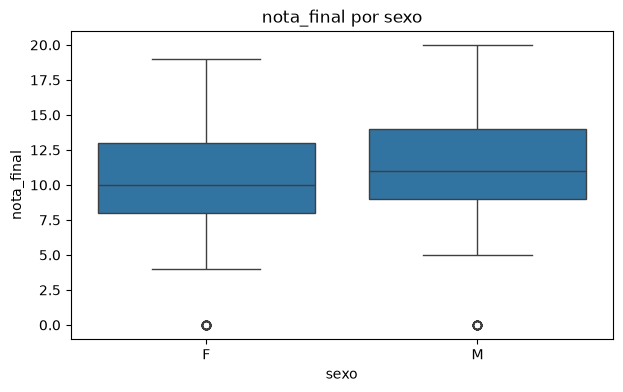


===== nota_final por regiao =====
        count  mean  std  min  25%   50%   75%   max
regiao                                              
R        88.0   9.5  4.6  0.0  7.0  10.0  12.0  19.0
U       307.0  10.7  4.6  0.0  9.0  11.0  14.0  20.0


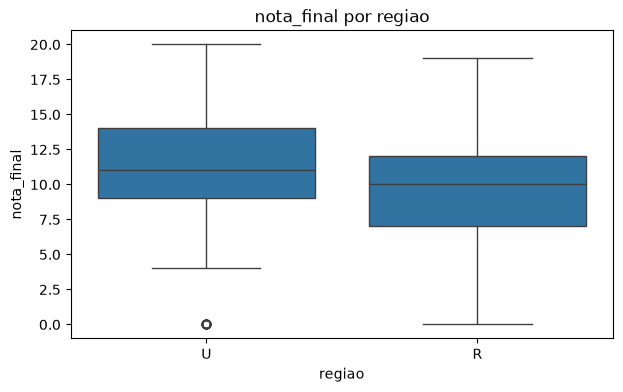


===== nota_final por desejo_de_ensino_superior =====
                           count  mean  std  min  25%   50%   75%   max
desejo_de_ensino_superior                                              
no                          20.0   6.8  4.8  0.0  0.0   8.0  10.0  13.0
yes                        375.0  10.6  4.5  0.0  9.0  11.0  14.0  20.0


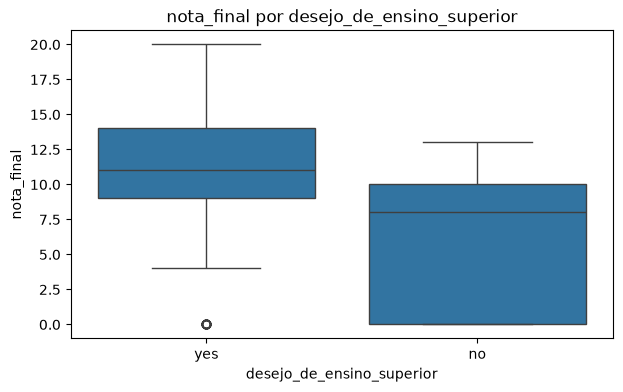


===== nota_final por tamanho_familia =====
                 count  mean  std  min  25%   50%   75%   max
tamanho_familia                                              
GT3              281.0  10.2  4.7  0.0  8.0  11.0  14.0  20.0
LE3              114.0  11.0  4.2  0.0  9.0  11.0  13.8  19.0


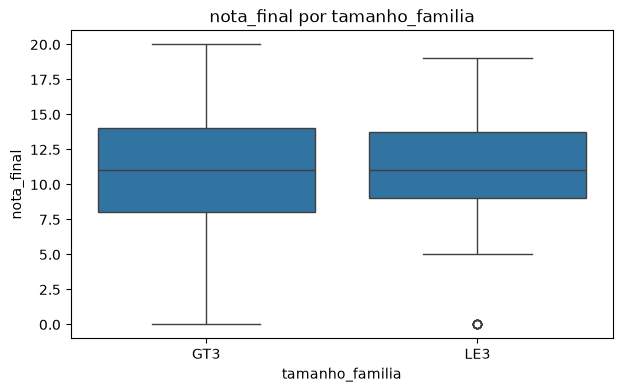


===== nota_final por convivencia_pais =====
                  count  mean  std  min  25%   50%   75%   max
convivencia_pais                                              
A                  41.0  11.2  4.3  0.0  9.0  11.0  13.0  19.0
T                 354.0  10.3  4.6  0.0  8.0  11.0  14.0  20.0


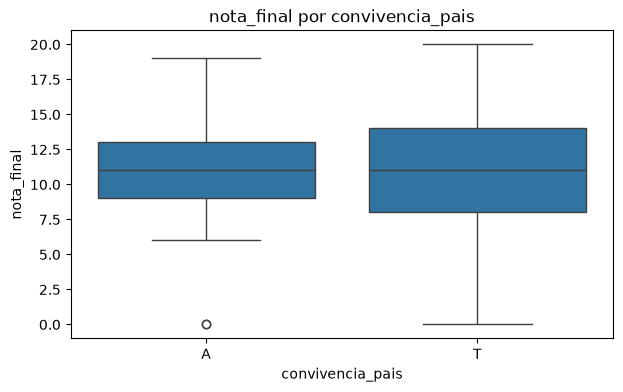


===== nota_final por trabalho_mae =====
              count  mean  std  min   25%   50%   75%   max
trabalho_mae                                               
at_home        59.0   9.2  4.7  0.0   8.0  10.0  12.5  19.0
health         34.0  12.1  4.2  0.0  10.0  13.0  15.0  20.0
other         141.0   9.8  4.4  0.0   8.0  11.0  13.0  19.0
services      103.0  11.0  4.8  0.0   9.0  11.0  14.5  19.0
teacher        58.0  11.1  4.4  0.0   9.0  11.0  14.0  19.0


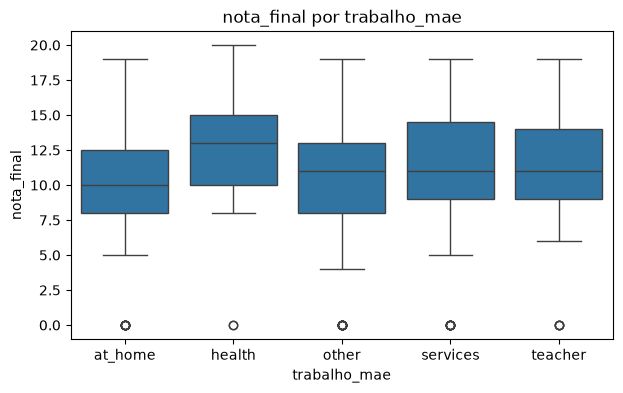


===== nota_final por trabalho_pai =====
              count  mean  std  min   25%   50%   75%   max
trabalho_pai                                               
at_home        20.0  10.2  5.3  0.0   8.8  11.0  13.2  19.0
health         18.0  11.6  3.2  7.0   9.0  11.0  14.0  18.0
other         217.0  10.2  4.5  0.0   8.0  11.0  13.0  19.0
services      111.0  10.3  4.5  0.0   9.0  11.0  13.0  20.0
teacher        29.0  12.0  5.5  0.0  10.0  14.0  16.0  19.0


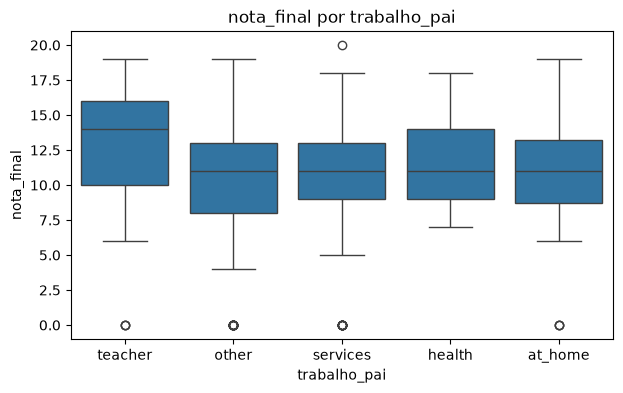


===== nota_final por motivo_escola =====
               count  mean  std  min  25%   50%   75%   max
motivo_escola                                              
course         145.0   9.8  4.9  0.0  8.0  10.0  13.0  19.0
home           109.0  10.3  4.6  0.0  8.0  11.0  13.0  19.0
other           36.0  11.2  3.8  0.0  9.8  11.0  13.0  19.0
reputation     105.0  11.1  4.3  0.0  9.0  11.0  14.0  20.0


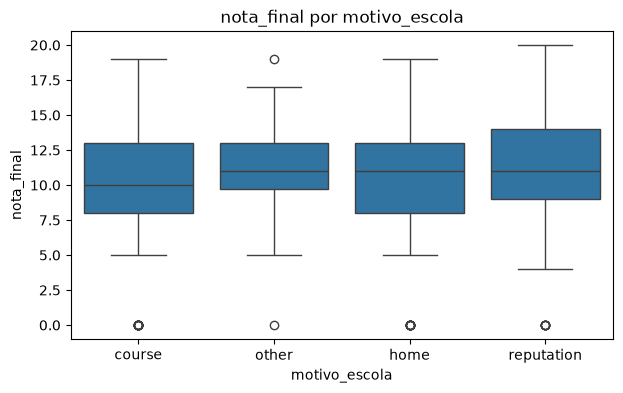


===== nota_final por guardiao_legal =====
                count  mean  std  min  25%   50%   75%   max
guardiao_legal                                              
father           90.0  10.7  4.5  0.0  9.0  11.0  14.0  18.0
mother          273.0  10.5  4.6  0.0  8.0  11.0  14.0  20.0
other            32.0   9.1  4.7  0.0  8.0   9.5  12.0  18.0


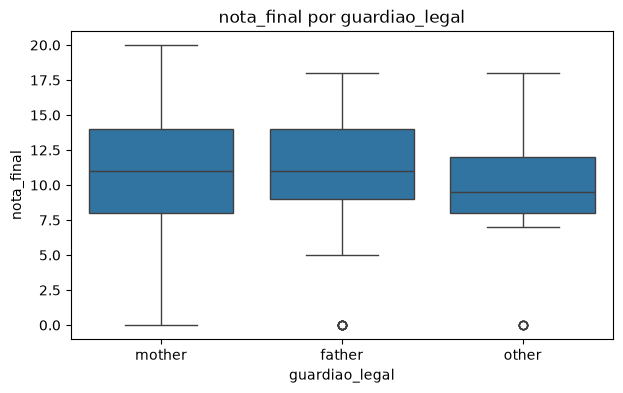

In [71]:
boxplots_nominais(df_mat, "nota_final", nominais)